# Palindromic Van Der Waerden Numbers pdw(2;3,t)

Consider the set of $N = \{1,\ldots,n\}$ , and let $O_C \subseteq N$ be integers which are colored "blue" in an arbitrary coloring $C$.  The highly efficient SAT algorithm invalidates 2-colorings with a 3-term progression in "blue" and a t-term progression in the other through contradictions in the following logic: 

$$
\begin{align*} O_C  \cap \lambda_{r} &\neq \lambda_{r} \\ O_C \cap \gamma_s &\neq \varnothing
 \end{align*}
$$

Where $\{ \lambda_r \} \subset \mathcal{P}(N)$ is the collection of 3-term progressions on N and $\{ \gamma_s \} \subset \mathcal{P}(N)$ is the collection of t-term progressions on N.  



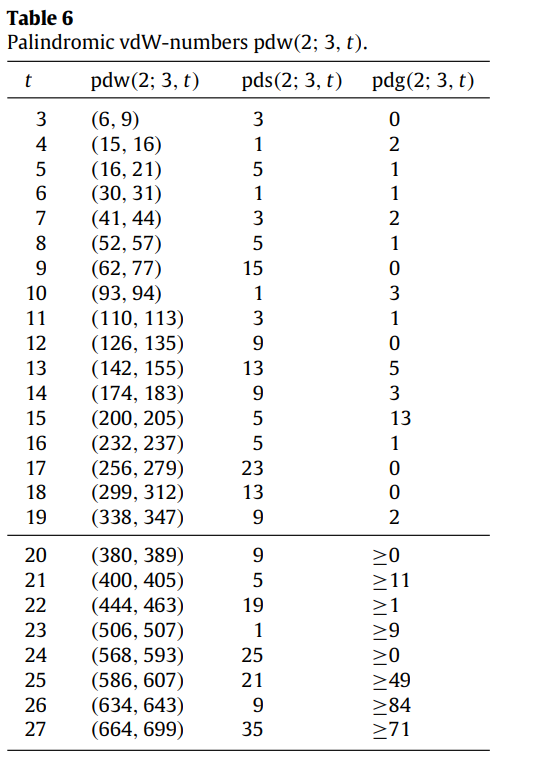

In Ahmed, Kullmann, and Snevily's publication <i> On the van der Waerden numbers w(2;3,t) </i> (2014), they introduced the palindromic van der Waerden numbers, and obtained values for pdw(2,3;t).  The goal of this notebook is to confirm their values for $3 \leq t \leq 19$, using both an iterative approach and the SAT solver and to compare efficiency.

## Preliminaries (Run These!)

In [3]:
import os
import time
load("VDWFunctions.sage")

## Iteratively Built Colorings Approach



Our code builds palindromic colorings of [1,n] iteratively beginning with two lists: one comprised of possible colorings of length 1, and another comprised of palindromic colorings of length 2. Each iteration builds new possible colorings by appending "0"s or "1"s to _each_ side of its predecessors (creating two new colorings for each previous coloring) and then checks for monochromatic arithmetic-progressions, which need only be done on the left-most entry due to previous checks. If a monochromatic arithmetic-progression is found, we cull the entry from the list. 

At each step, the lists are comprised of colorings of a fixed length, one of odd and one of even parity. _Eventually_, every possible coloring vanishes, as they contain a 3-term progression on "0"s or t-term progression on "1"s.  The palindromic van der Waerden number pdw(2;3,t) corresponds to (p,q) where p is the final coloring-length before the first empty list, and q is the value at which any colorings of length $\geq q$ necessarily vanish, yielding empty lists. 


In [ ]:
#Starting a total timer here
total_start = time.perf_counter()
#Checking pdw(2;3,t) for t from 3 to 20.
for t in range(3, 20):
    #Individual timers and outputs for each step
    start = time.perf_counter()
    result = v3pdw(t)
    elapsed = time.perf_counter() - start
    #Communicating the result and the elapsed time at each step
    print(f"pdw(2;3,{t}) = {result} | {elapsed:.2f}s", flush=True)
#Relaying the total runtime
total = time.perf_counter() - total_start
print(f"\nTotal runtime: {total:.2f}s")

pdw(2;3,3) = (6, 9) | 0.00s
pdw(2;3,4) = (15, 16) | 0.00s
pdw(2;3,5) = (16, 21) | 0.00s
pdw(2;3,6) = (30, 31) | 0.00s
pdw(2;3,7) = (41, 44) | 0.00s
pdw(2;3,8) = (52, 57) | 0.02s
pdw(2;3,9) = (62, 77) | 0.06s
pdw(2;3,10) = (93, 94) | 0.20s
pdw(2;3,11) = (110, 113) | 0.89s
pdw(2;3,12) = (126, 135) | 2.82s
pdw(2;3,13) = (142, 155) | 12.57s
pdw(2;3,14) = (174, 183) | 48.80s
pdw(2;3,15) = (200, 205) | 237.27s
pdw(2;3,16) = (232, 237) | 964.63s
pdw(2;3,17) = (256, 279) | 4769.21s


## SAT Solver

In [14]:
#AI DISCLOSURE: AI was used to install and implement the SAT Solver
load("SATSolver.sage")

In [24]:
#Starting a total timer here
total_start = time.perf_counter()
#Checking pdw(2;3,t) for t from 3 to 20.
for t in range(3, 20):
    #Individual timers and outputs for each step
    start = time.perf_counter()
    result = FindPVDW(t)
    elapsed = time.perf_counter() - start
    #Communicating the result and the elapsed time at each step
    print(f"pdw(2;3,{t}) = {result} | {elapsed:.2f}s", flush=True)
#Relaying the total runtime
total = time.perf_counter() - total_start
print(f"\nTotal runtime: {total:.2f}s")

Compiling tawSolver from source...
SAT solver compiled successfully!
pdw(2;3,3) = (6, 9) | 1.57s
pdw(2;3,4) = (15, 16) | 0.10s
pdw(2;3,5) = (16, 21) | 0.11s
pdw(2;3,6) = (30, 31) | 0.20s
pdw(2;3,7) = (41, 44) | 0.28s
pdw(2;3,8) = (52, 57) | 0.38s
pdw(2;3,9) = (62, 77) | 0.52s
pdw(2;3,10) = (93, 94) | 0.79s
pdw(2;3,11) = (110, 113) | 1.09s
pdw(2;3,12) = (126, 135) | 1.51s
pdw(2;3,13) = (142, 155) | 1.96s
pdw(2;3,14) = (174, 183) | 3.32s
pdw(2;3,15) = (200, 205) | 4.58s
pdw(2;3,16) = (232, 237) | 8.77s
pdw(2;3,17) = (256, 279) | 23.74s
pdw(2;3,18) = (299, 312) | 64.97s
pdw(2;3,19) = (338, 347) | 102.92s

Total runtime: 216.83s


While both algorithms confirm the paper's values, the SATSolver overwhelmingly outperforms the iteratively built colorings approach.

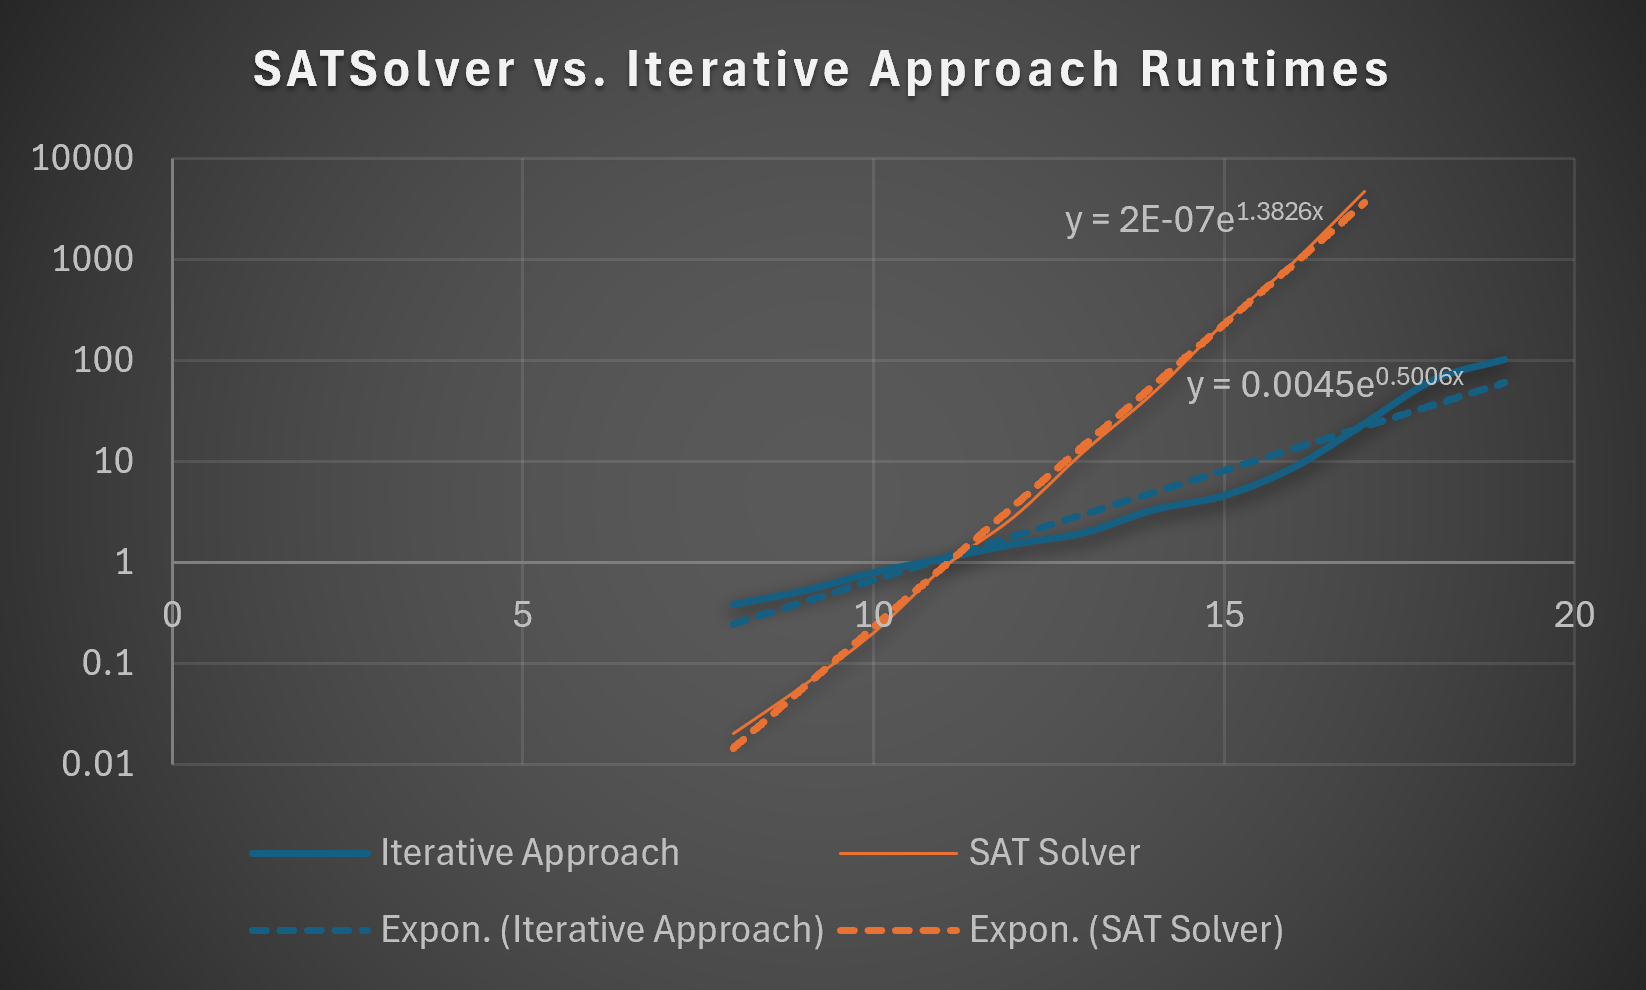

With a simple Excel exponential regression, we see an exponential growth rate in our iterative appraoch of $ \approx 3.985$ vs. an exponential growth rate of $\approx 1.650$ in our SAT Solver, which means for increasing values of $t$, the difference in efficiency will continue to grow.

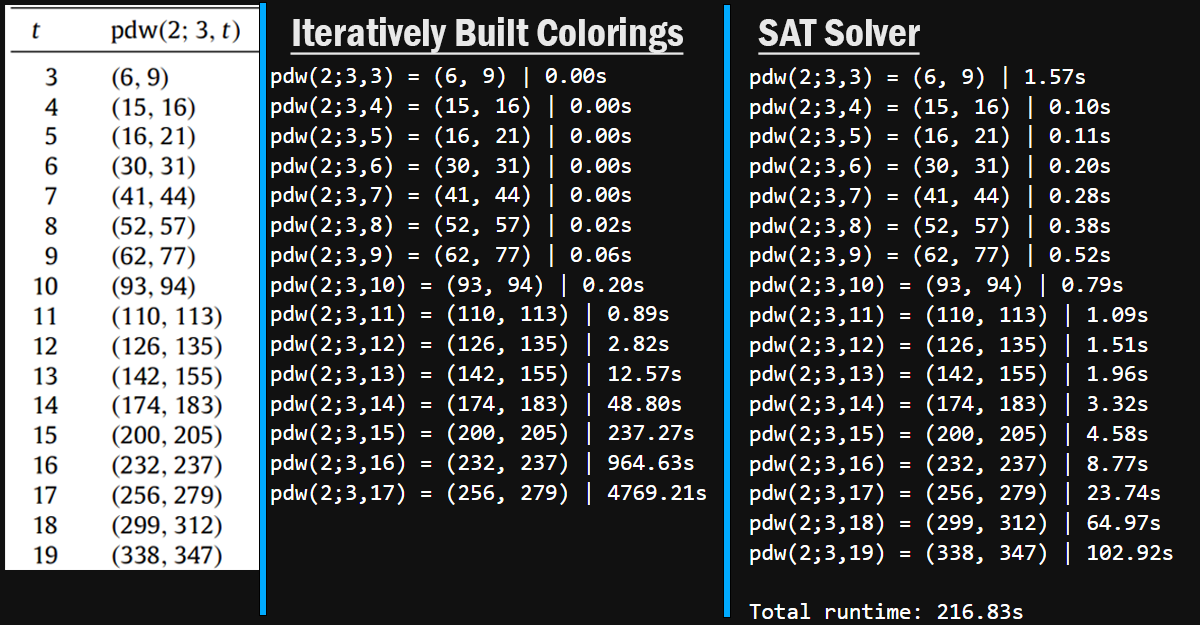

A quick AI assisted literature search returned no new results pertaining to the palindromic van der Waerden number since the 2014 publication.  AI was also employed to assist in implementing the SAT Solver in our code.

## References

Ahmed, T., Kullmann, O., & Snevily, H. (2014). On the van der Waerden numbers \(w(2;3,t)\). Discrete Applied Mathematics, 174, 27–51.